# Data analysis

Before building a model I wanted to understand what the target actually is, what moves the gas price and which of the 112 columns are useful. All numbers here use only the training period (Sep 2003 to Aug 2020), some charts also show the test years just for context.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.data import load_all
from src.features import same_month_average, storage_surplus

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

data = load_all()
train = data.loc[:config.TRAIN_END]

print(len(data), "months,", len(train), "train,", data["is_test"].sum(), "test")

252 months, 204 train, 48 test


### Dividing Columns to different categories

In [2]:
provided = [c for c in pd.read_csv(config.RAW_DIR / "data_train.csv", nrows=0).columns if c not in ("date", config.TARGET)]

print(len(provided), "input columns")
print("OECD leading indicators:", sum(c.startswith(("CLI_", "Composite_Leading")) for c in provided))
print("China PMI:", sum("PMI" in c for c in provided))
print("China industrial output:", sum(c.endswith("_YoY") for c in provided))
print("US gas statistics:", sum("Natural_Gas" in c for c in provided))

112 input columns
OECD leading indicators: 49
China PMI: 27
China industrial output: 4
US gas statistics: 6


In [3]:
# which columns start latest
data[provided].apply(lambda s: s.first_valid_index()).sort_values(ascending=False).head(8)

Construction_PMI                                         2021-01-31
Services_PMI                                             2021-01-31
Comprehensive_PMI                                        2017-01-31
M_PMI_Comp_Producer_Prices                               2016-02-29
M_PMI_Comp_Expected_Production_and_Business_Activities   2013-01-31
EU_Aggregated_LNG_System_Inventory                       2012-01-31
EU_Aggregated_Gas_Storage_Inventory                      2011-01-31
NM_PMI_Comp_New_Export_Orders                            2007-01-31
dtype: datetime64[ns]

Only 6 columns are about the US gas market itself (production, consumption, storage, imports, rigs). 76 are business surveys from OECD countries and China, which I don't expect to say much about a US regional gas price. Some China PMI columns only start between 2013 and 2021, EU storage in 2011-2012.

Speaking about US gas statistics, something I noticed in the last rows:

In [4]:
official = ["Natural_Gas_Total_Consumption_USA", "Total_Natural_Gas_Marketed_Production_USA",
            "Total_Natural_Gas_Underground_Storage_Volume_USA"]
data[official].tail(3)

,Natural_Gas_Total_Consumption_USA,Total_Natural_Gas_Marketed_Production_USA,Total_Natural_Gas_Underground_Storage_Volume_USA
date,,,
2024-06-30,2428030.0,3391900.0,7646200.0
2024-07-31,NaN,NaN,NaN
2024-08-31,NaN,NaN,NaN


The last two months are empty. These statistics come out about 2 months late, so on 31 August nobody knows August storage yet. Whenever I test one of these columns later I shift it by 2 months (`PUBLICATION_LAG_MONTHS` in config), otherwise the model would use data that wasn't available on the forecast date.

## The price

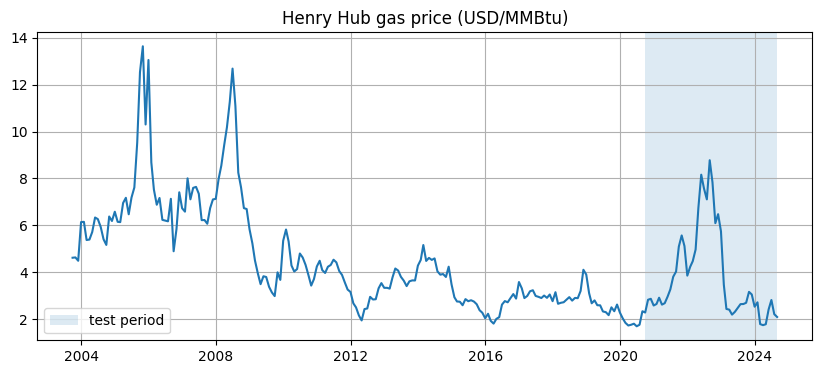

In [5]:
fig, ax = plt.subplots()
ax.plot(data["target"])
ax.axvspan(data.index[data["is_test"]][0], data.index[-1], alpha=0.15, label="test period")
ax.set_title("Henry Hub gas price (USD/MMBtu)")
ax.legend()
plt.show()

In [6]:
monthly_move = data["target"].pct_change().abs() * 100
print("average monthly move 2013 - Aug 2020:", round(monthly_move["2013-01":"2020-08"].mean(), 1), "%")
print("average monthly move in test period: ", round(monthly_move["2020-09":].mean(), 1), "%")

average monthly move 2013 - Aug 2020: 7.5 %
average monthly move in test period:  12.7 %


Before 2009 gas was expensive and jumped around a lot. After the shale boom it mostly stayed between 2 and 4 dollars. The test period has the 2021-2022 spike to almost 9 dollars and the crash after it.

The average monthly move in the test period is 12.7%, compared to 7.5% in 2013-2020. So I expect bigger errors on the test set than on anything I validate on, for any model.

## What is the target exactly?

The column is just called "Henry Hub gas price", but EIA publishes two Henry Hub prices: the spot price (gas delivered tomorrow) and the front-month futures price (NYMEX contract for gas delivered next month). I downloaded both from EIA and compared them with the target.

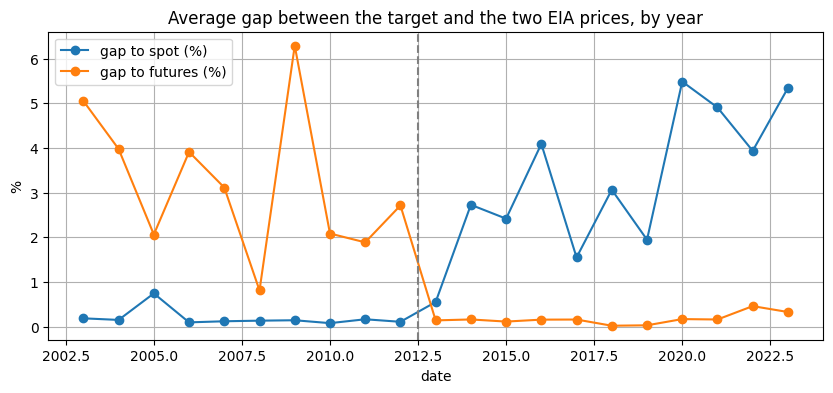

,until Dec 2012,from Jan 2013
gap to spot (%),0.20,3.70
gap to futures (%),3.06,0.19


In [7]:
gap = pd.DataFrame({
    "gap to spot (%)": (data["target"] / data["hh_spot"] - 1).abs() * 100,
    "gap to futures (%)": (data["target"] / data["fut_c1"] - 1).abs() * 100,
})

yearly = gap.groupby(gap.index.year).mean().loc[2003:2023]
ax = yearly.plot(marker="o", title="Average gap between the target and the two EIA prices, by year")
ax.axvline(2012.5, color="grey", linestyle="--")
ax.set_ylabel("%")
plt.show()

pd.DataFrame({"until Dec 2012": gap.loc[:"2012-12"].mean(), "from Jan 2013": gap.loc["2013-01":].mean()}).round(2)

Until December 2012 the target follows the spot price. From January 2013 it's the monthly average of the front-month futures price (within 0.2%). Probably several data sources was used to make this data set.
The whole test period is a futures price, so what I'm really forecasting is a futures price. For training I replace the pre-2013 values with the EIA futures price so the history is consistent (column `price` in `src/data.py`).

## Monthly average vs month-end values

The target is an average over the month. The market columns (oil, stock indices, Bloomberg commodity indices) are the value on the last day of the month. For example the S&P 500 value for March 2020 is 2584.59, which is the close on 31 March and not the March average.

In [8]:
data.loc["2020-03", ["GSPC_INDX", "DJI_INDX"]]

,GSPC_INDX,DJI_INDX
date,,
2020-03-31,2584.59,21917.2


If gas jumps in the last week of a month, that month's average barely moves, but next month's average will be higher. BCOMNG_INDX  follows gas futures and is a month-end value, so it should show this.

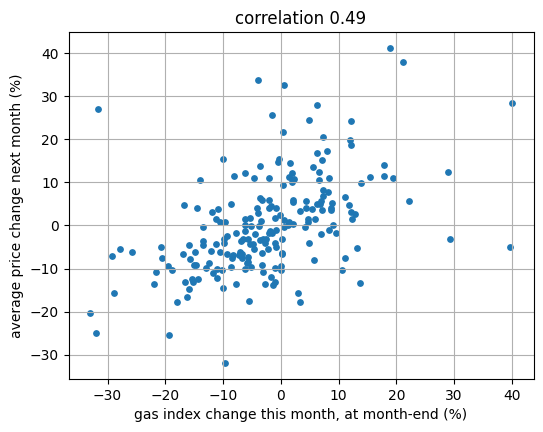

In [9]:
index_change = train["BCOMNG_INDX"].pct_change() * 100
next_month_change = train["price"].pct_change().shift(-1) * 100

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(index_change, next_month_change, s=15)
ax.set_xlabel("gas index change this month, at month-end (%)")
ax.set_ylabel("average price change next month (%)")
ax.set_title(f"correlation {index_change.corr(next_month_change):.2f}")
plt.show()

Correlation 0.49. When the gas index goes up during a month, the average price tends to go up the month after. It's known on the forecast date, so I can use it. 

## What drives the gas price

US gas is mostly produced and used in America, so the price depends on the local balance: production on one side, consumption and LNG exports on the other. Storage is the buffer, filled April to October and emptied November to March. Traders usually look at storage compared to its 5-year average.

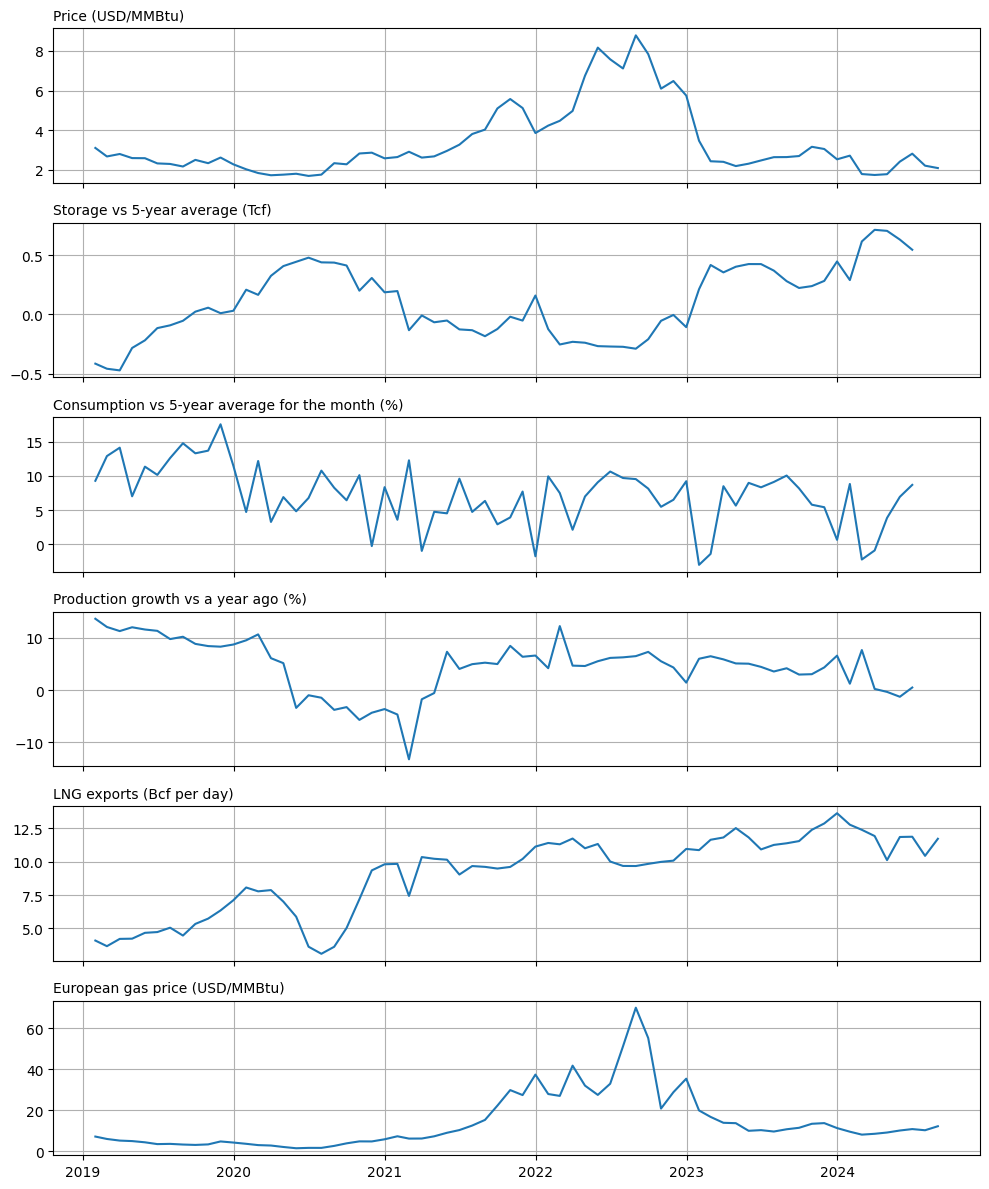

In [10]:
consumption = data["Natural_Gas_Total_Consumption_USA"]
production = data["Total_Natural_Gas_Marketed_Production_USA"]
panels = {
    "Price (USD/MMBtu)": data["target"],
    "Storage vs 5-year average (Tcf)": storage_surplus(data),
    "Consumption vs 5-year average for the month (%)": (consumption / same_month_average(consumption) - 1) * 100,
    "Production growth vs a year ago (%)": (production / production.shift(12) - 1) * 100,
    "LNG exports (Bcf per day)": data["lng_exports"] / data.index.days_in_month / 1000,
    "European gas price (USD/MMBtu)": data["europe_gas"],
}

fig, axes = plt.subplots(len(panels), 1, figsize=(10, 12), sharex=True)
for ax, (title, series) in zip(axes, panels.items()):
    ax.plot(series.loc["2019-01":])
    ax.set_title(title, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [11]:
temperature = (train["high_temperature"] + train["low_temperature"]) / 2
cons = train["Natural_Gas_Total_Consumption_USA"]
winter = train.index.month.isin([11, 12, 1, 2, 3])
summer = train.index.month.isin([6, 7, 8, 9])
price_vs_own_average = train["price"] / train["price"].rolling(12).mean() - 1

print("winter, temperature vs consumption:", round(cons[winter].corr(temperature[winter]), 2))
print("summer, temperature vs consumption:", round(cons[summer].corr(temperature[summer]), 2))
print("storage surplus vs price:", round(storage_surplus(train).corr(price_vs_own_average), 2))

winter, temperature vs consumption: -0.56
summer, temperature vs consumption: 0.49
storage surplus vs price: -0.34


Colder winter means more gas burned (-0.56), hotter summer too (+0.49), and more gas in storage goes with a lower price (-0.34).

## The dollar

The task description mentions that the dollar index usually moves against commodity prices, so I checked it.

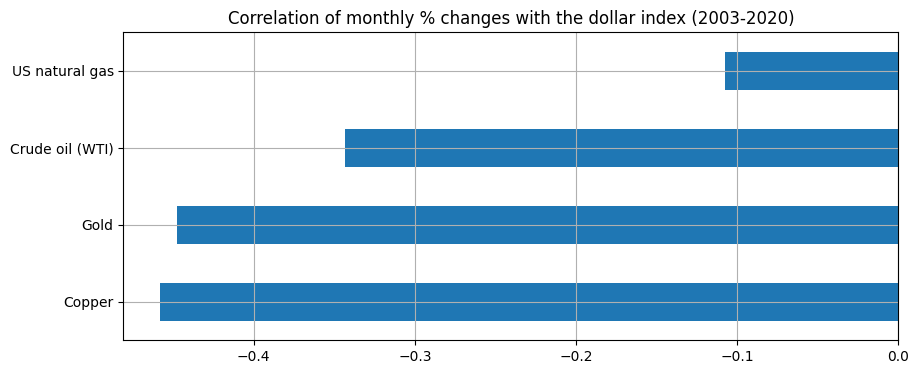

Copper            -0.46
Gold              -0.45
Crude oil (WTI)   -0.34
US natural gas    -0.11
dtype: float64

In [12]:
dollar = train["DXY_INDX"].pct_change()
others = {"Copper": "BCOMHG_INDX", "Gold": "BCOMGC_INDX", "Crude oil (WTI)": "WTI_Crude_Oil",
          "US natural gas": "price"}
dollar_corr = pd.Series({name: dollar.corr(train[col].pct_change()) for name, col in others.items()})

dollar_corr.sort_values().plot.barh(title="Correlation of monthly % changes with the dollar index (2003-2020)")
plt.show()
dollar_corr.round(2)

True for copper, gold and oil, which are traded worldwide in dollars. For US gas it's only -0.11. I still tested the dollar as a feature in model selection and it didn't help.

### Columns Selection


I also wanted to check for each column if it moves this month, does the gas price move next month?

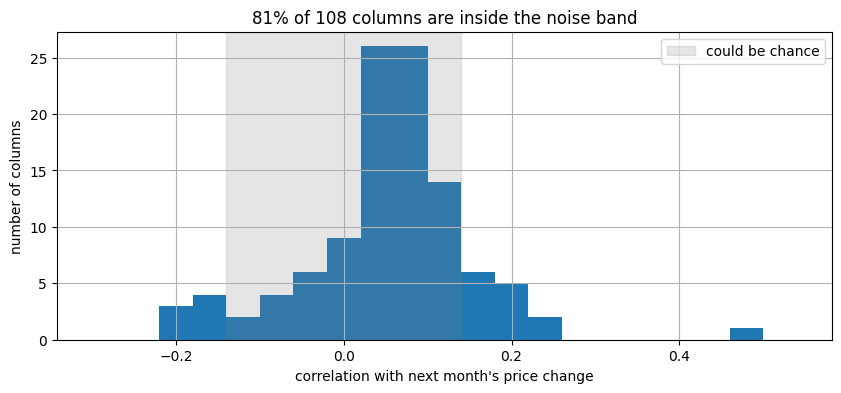

BCOMNG_INDX                                                                 0.49
Composite_Leading_Indicator_JPN                                             0.24
Real_Estate_Floor_Space_of_Commercialized_Buildings_Sold_Accumulated_YoY    0.22
CLI_Comp_Stocks_JPN                                                        -0.21
Motor_Vehicles_Accumulated_YoY                                              0.21
CLI_Comp_Sales_Expectations_JPN                                             0.20
dtype: float64

In [13]:
next_change = train["price"].pct_change().shift(-1)

corrs = {}
for name in provided:
    s = train[name]
    change = s.pct_change(fill_method=None) if (s.dropna() > 0).all() else s.diff()
    both = change.notna() & next_change.notna()
    if both.sum() >= 60:   
        corrs[name] = change[both].corr(next_change[both])
screen = pd.Series(corrs).sort_values(key=abs, ascending=False)

noise = 0.14   # ~ 2/sqrt(200 months), this is our treshold 
plt.hist(screen, bins=np.arange(-0.30, 0.56, 0.04))
plt.axvspan(-noise, noise, color="grey", alpha=0.2, label="could be chance")
plt.xlabel("correlation with next month's price change")
plt.ylabel("number of columns")
plt.title(f"{(screen.abs() < noise).mean():.0%} of {len(screen)} columns are inside the noise band")
plt.legend()
plt.show()

screen.head(6).round(2)

Columns that are maybe are not noise

In [14]:
screen[screen.abs() >= noise].round(2)

BCOMNG_INDX                                                                 0.49
Composite_Leading_Indicator_JPN                                             0.24
Real_Estate_Floor_Space_of_Commercialized_Buildings_Sold_Accumulated_YoY    0.22
CLI_Comp_Stocks_JPN                                                        -0.21
Motor_Vehicles_Accumulated_YoY                                              0.21
CLI_Comp_Sales_Expectations_JPN                                             0.20
CLI_Comp_Finished_Goods_Stocks_Tendency_DEU                                -0.20
CLI_Comp_Construction_JPN                                                   0.20
CLI_Comp_Terms_Of_Trade_KOR                                                -0.20
CLI_Comp_Business_Situation_USA                                             0.20
CLI_Comp_Hours_JPN                                                          0.19
CLI_Comp_Consumer_Prices_GBR                                                0.18
CLI_Comp_Bank_Activity_JPN  

About 80% of the columns look like noise. The gas futures index is far ahead of everything else.

Most of the other columns outside the band are OECD leading indicators. I decided not to use them. They get revised after they are published, so the history in the file isn't what someone would have seen at the time, and I don't think a Japanese business survey would move US gas prices. With 108 columns, around 5 would also pass 0.14 just by chance.

What I decided per group:

- BCOMNG_INDX: keep
- WTI_Crude_Oil: test. 
- US gas statistics: test, with the 2-month lag
- Boston temperature: test
- OECD indicators (49), China surveys (31), US macro: drop
- EU storage: only for analysis, because it only starts in 2011-2012 (not enough data)

## Storage and the futures curve

Storage is the classic gas indicator, so why not just put it into the model? My guess was that the futures market already reacts to the storage reports. If storage is full, gas is cheap now but later months should trade higher.

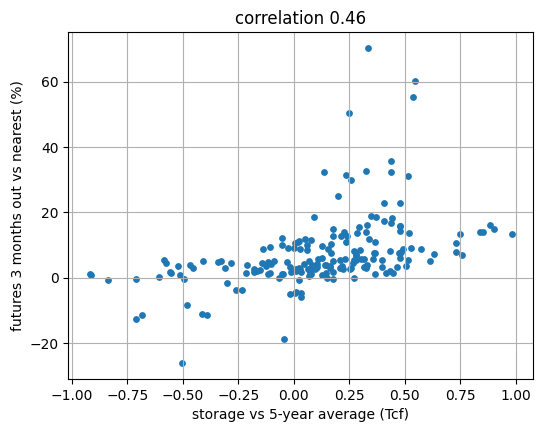

In [15]:
surplus = storage_surplus(data).loc[train.index]
curve_3m = (train["fut_c4"] / train["fut_c1"] - 1) * 100

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(surplus, curve_3m, s=15)
ax.set_xlabel("storage vs 5-year average (Tcf)")
ax.set_ylabel("futures 3 months out vs nearest (%)")
ax.set_title(f"correlation {surplus.corr(curve_3m):.2f}")
plt.show()

That's what happens (correlation 0.46). With more gas in storage than usual, the later contracts trade above the nearest one. With less gas, the curve is flat or goes down.

So the futures curve already has the storage information, and without the 2 month delay. I decided to use the futures curve itself as the starting point of the forecast. Further, adding storage on top made the model worse, which fits this.

### External data

I also to seek some information in Internet that could help me, and I added this datasets to our data, in hope that it will help us.

- NYMEX gas futures, contracts 1 to 4, monthly (EIA). The market's own expectation for the next months, and also how I found out what the target is
- Henry Hub spot price (EIA), to check the target before 2013
- US LNG exports (EIA), the biggest new source of demand since 2016
- European gas price (IMF, via FRED), important for 2021-2022

One problem: EIA stopped publishing futures prices in April 2024. For the last four forecast dates (May to August 2024) I use the usual seasonal shape of the curve instead.